In [20]:
import numpy as np
import pandas as pd
import struct
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


In [21]:
data = pd.read_csv("cifar-10.csv")

print(data.head())

   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...          58          65          59          46   
1      142      111  ...          42          67         101         122   
2      253      253  ...          83          80          69          66   
3       32       43  ...          39          59          42          44   
4      189      189  ...          88          85          82          83   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070  pixel_3071  label  
0        

In [22]:
X = data.drop("label", axis=1).values
y = data["label"].values

print("Training", X.shape)
print("Testing", y.shape)

Training (50000, 3072)
Testing (50000,)


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [24]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [25]:
model = keras.Sequential([
    keras.Input(shape=(3072,)),

    layers.Dense(512, activation="relu"),
    layers.Dense(256, activation="relu"),

    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 512)                 │       1,573,376 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.3046 - loss: 1.9359 - val_accuracy: 0.3503 - val_loss: 1.8188
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.3800 - loss: 1.7299 - val_accuracy: 0.4002 - val_loss: 1.6913
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.4131 - loss: 1.6387 - val_accuracy: 0.4185 - val_loss: 1.6412
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.4293 - loss: 1.5885 - val_accuracy: 0.4179 - val_loss: 1.6378
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.4550 - loss: 1.5271 - val_accuracy: 0.4618 - val_loss: 1.5298
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.4617 - loss: 1.5047 - val_accuracy: 0.4358 - val_loss: 1.5921
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.4724 - loss: 1.4749 - val_accuracy: 0.4613 - val_loss: 1.5372
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.4827 - loss: 1.4445 - val_a

In [28]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4747 - loss: 1.4920    
Test Loss: 1.4919906854629517
Test Accuracy: 0.474700003862381


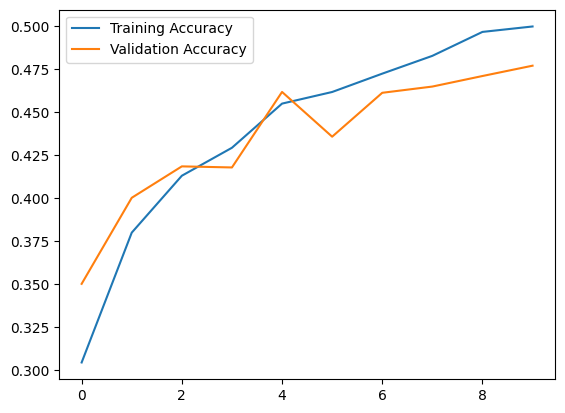

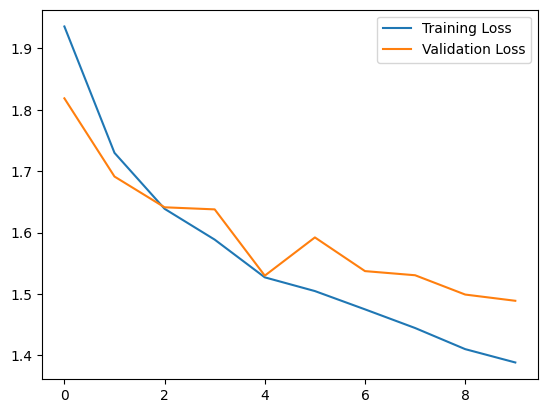

In [29]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


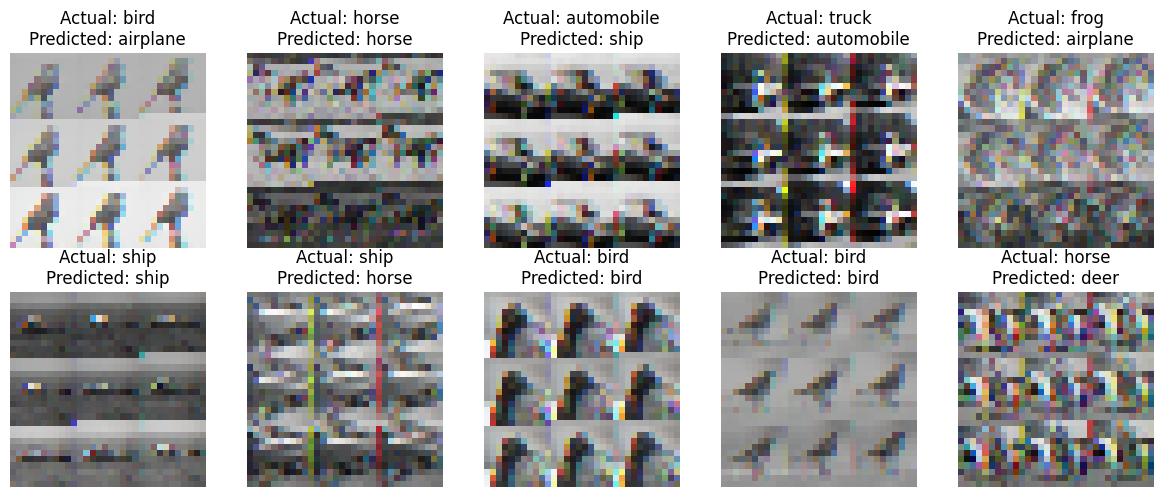

In [34]:
predictions = model.predict(X_test)
classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
plt.figure(figsize=(12,5))

for i in range(10):
    plt.subplot(2,5,i+1)

    actual = y_test.iloc[i]
    predicted = np.argmax(predictions[i])

    plt.imshow(X_test[i].reshape(32,32,3))

    plt.title(
        f"Actual: {classes[actual]}\nPredicted: {classes[predicted]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()